In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
%matplotlib inline 
sns.set()

import warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12,6)

In [2]:
data  = pd.read_csv("driver_data.csv")

In [3]:
# Select features for scaling
features_to_scale = data[['Distance_Feature', 'Speeding_Feature']]

# Initialize and apply StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features_to_scale)

# Create a new DataFrame with scaled features for clustering
# This keeps the original 'data' DataFrame intact for other uses (like plotting with original scales)
data_scaled = pd.DataFrame(scaled_features, columns=['Distance_Feature_Scaled', 'Speeding_Feature_Scaled'])

In [4]:
# Determine optimal k using the Elbow Method
inertia_values = []
possible_k_values = range(1, 11) # Test k from 1 to 10

for k in possible_k_values:
    kmeans_elbow = KMeans(n_clusters=k, n_init='auto', random_state=42)
    kmeans_elbow.fit(data_scaled) # Use scaled data
    inertia_values.append(kmeans_elbow.inertia_)

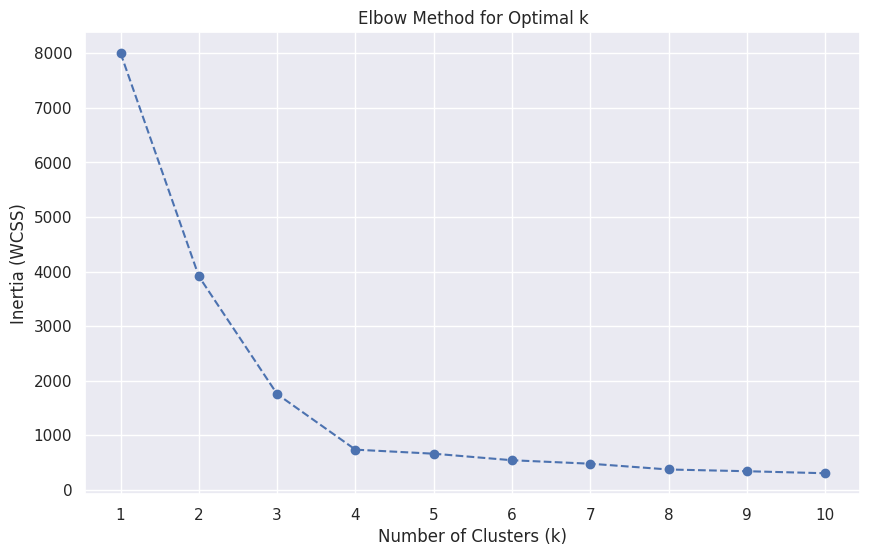

In [5]:
# Plot the Elbow curve
plt.figure(figsize=(10, 6))
plt.plot(possible_k_values, inertia_values, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(possible_k_values)
plt.grid(True)
plt.show()

In [6]:
data.head()

,Distance_Feature,Speeding_Feature
0,71.24,28
1,52.53,25
2,64.54,27
3,55.69,22
4,54.58,25


In [7]:
data.shape

(4000, 2)

In [8]:
data.info

<bound method DataFrame.info of       Distance_Feature  Speeding_Feature
0                71.24                28
1                52.53                25
2                64.54                27
3                55.69                22
4                54.58                25
...                ...               ...
3995            160.04                10
3996            176.17                 5
3997            170.91                12
3998            176.14                 5
3999            168.03                 9

[4000 rows x 2 columns]>

In [9]:
data.describe()

,Distance_Feature,Speeding_Feature
count,4000.000000,4000.000000
mean,76.041522,10.721000
std,53.469563,13.708543
min,15.520000,0.000000
25%,45.247500,4.000000
50%,53.330000,6.000000
75%,65.632500,9.000000
max,244.790000,100.000000


In [10]:
data.isnull().sum()

Distance_Feature    0
Speeding_Feature    0
dtype: int64

In [11]:
kmeans = KMeans(n_clusters=2, n_init='auto', random_state=42)

In [12]:
kmeans.fit(data_scaled)

,n_clusters,2
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [13]:
kmeans.cluster_centers_

array([[-0.48581565, -0.13816168],
       [ 1.94630276,  0.55351131]])

In [14]:
print(kmeans.labels_)

[0 0 0 ... 1 1 1]


In [15]:
kmeans.fit(data_scaled)

,n_clusters,2
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [16]:
print(type(kmeans.labels_))
unique,counts = np.unique(kmeans.labels_, return_counts=True)
print(dict(zip(unique,counts)))

<class 'numpy.ndarray'>
{np.int32(0): np.int64(3201), np.int32(1): np.int64(799)}


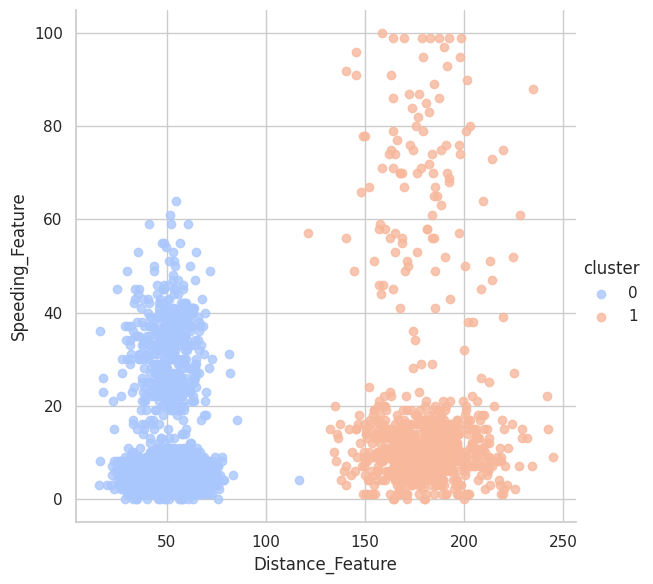

In [17]:
data['cluster'] = kmeans.labels_
sns.set_style('whitegrid')
sns.lmplot(x='Distance_Feature', y='Speeding_Feature', data=data,hue='cluster',palette='coolwarm',height=6,aspect=1,fit_reg=False)

In [18]:
kmeans_4 = KMeans(n_clusters=4, n_init='auto', random_state=42)
kmeans_4.fit(data_scaled)
print(kmeans_4.cluster_centers_)
unique,counts = np.unique(kmeans_4.labels_, return_counts=True)
print(dict(zip(unique,counts)))

[[-0.48678423 -0.40249736]
 [ 1.95263225 -0.0139714 ]
 [-0.47952334  1.57909169]
 [ 1.90400473  4.34582367]]
{np.int32(0): np.int64(2774), np.int32(1): np.int64(695), np.int32(2): np.int64(427), np.int32(3): np.int64(104)}


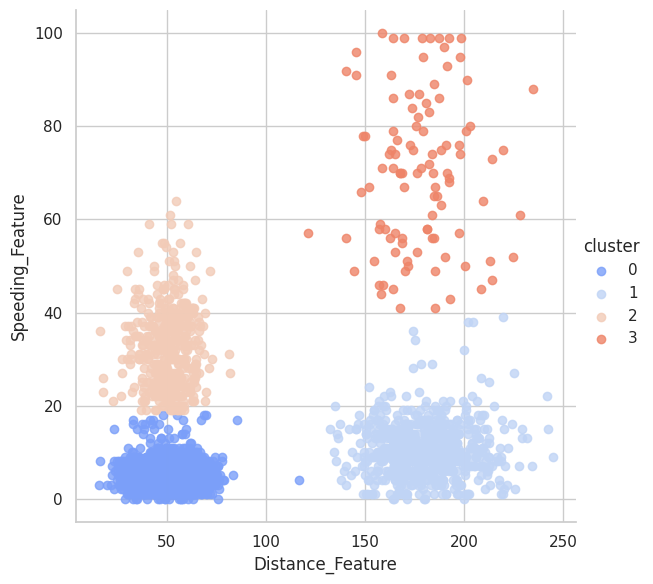

In [19]:
data['cluster'] = kmeans_4.labels_
sns.set_style('whitegrid')
sns.lmplot(x='Distance_Feature', y='Speeding_Feature', data=data,hue='cluster',palette='coolwarm',height=6,aspect=1,fit_reg=False)